# Shape-Shifting Hands & Co-Design Baselines

In this notebook, we introduce the MorphHand, the environments that use it (`RotateInHand` and `HandPickUp`), as well as a brief intro on how to set up and run checkpoints from **codesign-baselines**.

## 1. Environment & `codesign-baselines` Setup

Make sure you ran https://github.com/camral/codesign-gym/tree/main#basic-install beforehand.

The checkpoints in this notebook were trained with **codesign-baselines**, which contains a set of agents to get started with. Clone it next to `codesign-gym` and install it into the same environment (in a terminal, from the folder containing `codesign-gym`, with the environment active):

```bash
git clone https://github.com/camral/codesign-baselines.git
uv pip install -e codesign-baselines --no-sources
```

This installs the training dependencies too (W&B, nevergrad, ...) and keeps the `mujoco_warp` fork that the MorphHand needs, so you can also launch the training runs in Section 7. If your notebook kernel was already running, restart it afterwards.

Let's check if our setup is correct, and get the checkpoint directory:

In [1]:
import os
import sys
from pathlib import Path

# Configure offscreen GL on macOS *before* importing mujoco / codesign_gym.
if sys.platform == "darwin":
    os.environ.setdefault("MUJOCO_GL", "cgl")

import matplotlib.pyplot as plt
import mujoco
import numpy as np
import torch
from IPython.display import Image as ShowImage, display
from PIL import Image, ImageDraw, ImageFont

from codesign_gym import make, make_vec
from common.codesign_adapter import make_baseline_vec
from common.embodiment_conditioning import condition_observation
from fasttd3_cmaes.normalization import load_policy

DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
SEED = 4
np.random.seed(SEED)
torch.manual_seed(SEED)

RUNS_DIR = Path("runs")
CKPT_DIR = Path("hand_checkpoint_data")
RUNS_DIR.mkdir(exist_ok=True)

print(f"Platform: {sys.platform} | Device: {DEVICE}")
print("Checkpoints:", [p.name for p in sorted(CKPT_DIR.glob("*.pt"))])

Platform: darwin | Device: cpu
Checkpoints: ['smallhammer_codesign.pt', 'smallhammer_flat_mid.pt']


Some display/pad layout helpers for later:

In [2]:
def save_gif(frames, path, *, frame_every=2, control_dt=0.04, scale=1):
    imgs = [Image.fromarray(f[::scale, ::scale] if scale > 1 else f) for f in frames]
    imgs[0].save(path, save_all=True, append_images=imgs[1:],
                 duration=max(20, int(1000 * control_dt * frame_every)), loop=0)
    display(ShowImage(filename=str(path)))


def label_frame(frame, text, *, scale=1):
    img = Image.fromarray(frame[::scale, ::scale] if scale > 1 else frame)
    banner_h = 34 if scale == 1 else 26
    canvas = Image.new("RGB", (img.width, img.height + banner_h), (22, 26, 33))
    canvas.paste(img, (0, banner_h))
    font = ImageFont.load_default(size=16 if scale == 1 else 12)
    ImageDraw.Draw(canvas).text((10, 8 if scale == 1 else 6), text, fill=(245, 245, 245), font=font)
    return np.asarray(canvas)


def zoom_camera(env, factor=0.52):
    raw = getattr(env, "env", env)
    if raw.camera is None:
        env.render()
    raw.camera.distance *= factor


def pad_layout(env):
    raw = getattr(env, "env", env)
    p = raw._pads
    slices, shapes = {}, {}
    for hfield_id, rows, cols, start, count in zip(p["hfield"], p["nrow"], p["ncol"], p["col0"], p["ncell"]):
        name = mujoco.mj_id2name(raw.m, mujoco.mjtObj.mjOBJ_HFIELD, int(hfield_id))
        slices[name] = slice(int(start), int(start) + int(count))
        shapes[name] = (int(rows), int(cols))
    return slices, shapes

## 2. What Can MorphHand Do? (`RotateInHand-Cube`)

The MorphHand uses heightfield pads on its palm and fingers to provide fast post-compile deformation. It allows complex, non-convex geometry without needing convex decomposition. Its embodiment vector represents the following:
- **Pad cells (`[0 : n_cell]` in `[0, 1]`):** control each pad cell's elevation. Optionally, each heightfield is subdivided, and its subdivisions are fit through a quadratic spline for smoother geometry.
- **Link offsets (`[-3 :]` in `[-1, 1]`, each ±15 mm):** `finger_spacing`, `finger_width`, and `thumb_width`.

Setting `color_deforms=True` paints pad relief from blue (`0.0`) to red (`1.0`).

Let's inspect the spaces and compare two hand shapes side by side.

[codesign-gym] make_vec('RotateInHand-Cube', num_envs=2): instantiating
[codesign-gym] make_vec('RotateInHand-Cube', num_envs=2): success
Observation: (57,) | Action: (19,) | Embodiment: (224,)
Pads: {'palm': (10, 8), 'rf_proximal_x': (3, 5), 'rf_middle_x': (3, 4), 'rf_tip_x': (3, 3), 'mf_proximal_x': (3, 5), 'mf_middle_x': (3, 4), 'mf_tip_x': (3, 3), 'ff_proximal_x': (3, 5), 'ff_middle_x': (3, 4), 'ff_tip_x': (3, 3), 'th_proximal_x': (3, 5), 'th_tip_x': (3, 6)}
Module envs.rotate_in_hand.rotate_in_hand_kernels 5aa7287 load on device 'cpu' took 12399.90 ms  (compiled)


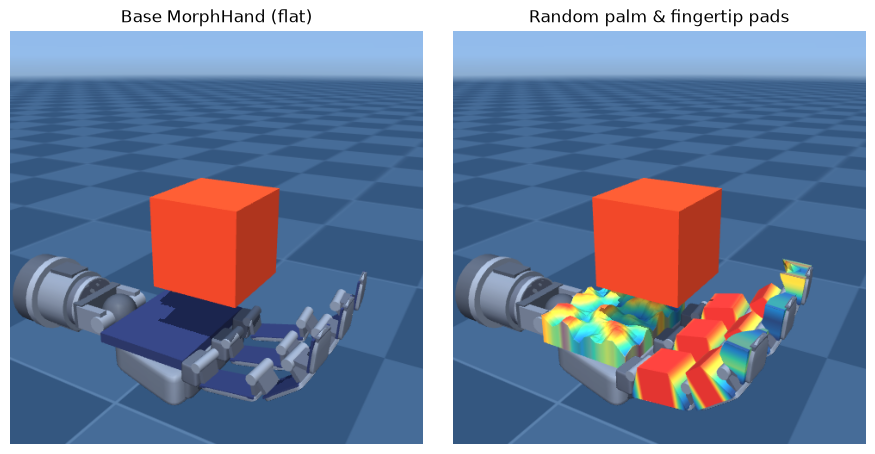

In [3]:
# 2 envs in parallel to compare them side-by-side
env, embodiment = make_vec("RotateInHand-Cube", 2, device=DEVICE, render_mode="rgb_array", color_deforms=True)
pads, pad_shapes = pad_layout(env)
print("Observation:", env.single_observation_space.shape, "| Action:", env.single_action_space.shape,
      "| Embodiment:", env.embodiment_space.shape)
print("Pads:", pad_shapes)

# let's set some offsets! the finger sections from palm to fingertips are proximal, middle, tip.
rng = np.random.default_rng(SEED)
custom_hand = embodiment.copy()

custom_hand[pads["palm"]]     = rng.uniform(0, 1, custom_hand[pads["palm"]].shape)

custom_hand[pads["rf_proximal_x"]] = np.ones(custom_hand[pads["rf_proximal_x"]].shape)
custom_hand[pads["mf_proximal_x"]] = np.ones(custom_hand[pads["mf_proximal_x"]].shape)
custom_hand[pads["ff_proximal_x"]] = np.ones(custom_hand[pads["ff_proximal_x"]].shape)

custom_hand[pads["rf_middle_x"]] = np.ones(custom_hand[pads["rf_middle_x"]].shape)
custom_hand[pads["mf_middle_x"]] = np.ones(custom_hand[pads["mf_middle_x"]].shape)
custom_hand[pads["ff_middle_x"]] = np.ones(custom_hand[pads["ff_middle_x"]].shape)

custom_hand[pads["rf_tip_x"]] = rng.uniform(0, 1, custom_hand[pads["rf_tip_x"]].shape)
custom_hand[pads["mf_tip_x"]] = rng.uniform(0, 1, custom_hand[pads["mf_tip_x"]].shape)
custom_hand[pads["ff_tip_x"]] = rng.uniform(0, 1, custom_hand[pads["ff_tip_x"]].shape)
custom_hand[pads["th_tip_x"]]  = rng.uniform(0, 1, custom_hand[pads["th_tip_x"]].shape)

custom_hand[-3:] = [0.8, 0.4, -0.7]  # finger spacing, finger width, thumb width

obs, rejected, _ = env.reset(seed=SEED, embodiment=np.stack([embodiment, custom_hand]))
assert not rejected.any()
zoom_camera(env)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, idx, title in zip(axes, (0, 1), ("Base MorphHand (flat)", "Random palm & fingertip pads")):
    ax.imshow(env.render(env_idx=idx))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
env.close()

### Live Morphing

MorphHand supports mid-episode embodiment changes without re-compilation via `env.step(action, embodiment=design)`. Let's send a traveling sine wave across every pad!

In [4]:
def wave_design(base, pad_slices, pad_shapes, t, *, omega=0.25, ramp_steps=12):
    design = base.copy()
    ramp = min(1.0, t / ramp_steps)
    for name, slc in pad_slices.items():
        rows, cols = pad_shapes[name]
        wave = ramp * (0.5 + 0.5 * np.sin(2.0 * np.pi * np.linspace(0.0, 1.0, cols) + omega * t))
        design[slc] = np.broadcast_to(wave, (rows, cols)).ravel()
    return design


env, base = make("RotateInHand-Cube", device=DEVICE, render_mode="rgb_array", color_deforms=True)
env_pads, env_shapes = pad_layout(env)
obs, rejected, _ = env.reset(seed=SEED, embodiment=base)
zoom_camera(env)

zero_action = np.zeros(env.action_space.shape, dtype=np.float32)
frames = [env.render()]
for t in range(1, 101):
    obs, reward, terminated, truncated, info = env.step(
        zero_action, embodiment=wave_design(base, env_pads, env_shapes, t)
    )
    if t % 2 == 0:
        frames.append(env.render())
env.close()

print(f"Rendered {len(frames)} frames (4.0 s simulated).")
save_gif(frames, RUNS_DIR / "morphhand_wave.gif", frame_every=2)

[codesign-gym] make('RotateInHand-Cube', num_envs=1): instantiating
[codesign-gym] make('RotateInHand-Cube', num_envs=1): success
Module mujoco_warp._src.derivative 2ae6b19 load on device 'cpu' took 6403.99 ms  (compiled)
Module _next_time_builder__locals___next_time_169f5f53 4efc1cd load on device 'cpu' took 1.28 ms  (error)


WarpCodegenKeyError: 'Error while parsing function "_next_activation" at /Users/ruth/notebook-test/codesign-gym/.venv/lib/python3.12/site-packages/mujoco_warp/_src/forward.py:246:\n  actuator_dynprm_id = worldid % actuator_dynprm.shape[0]\n;Referencing undefined symbol: actuator_dynprm'


## 3. Co-Design vs. Flat Pads on `HandPickUp-SmallHammer`

In **`HandPickUp-SmallHammer`**, MorphHand must lift a slim 0.43 kg hammer and hold it upright against random perturbation torques.

Inside `hand_checkpoint_data/`, we have two checkpoints trained via FastTD3:
- `smallhammer_flat_mid.pt` — trained on a fixed embodiment(pads at `0.5`, link offsets at `0.0`).
- `smallhammer_codesign.pt` — trained with FastTD3 for the policy + CMA-ES for the embodiment.

Let's set up some helpers first:

In [ ]:
def load_hand_checkpoint(path):
    config, policy = load_policy(path, DEVICE, compile=False)
    return config, policy, np.asarray(config["design"], dtype=np.float32)


@torch.no_grad()
def evaluate_hand(env, policy, design, *, seed=SEED, max_steps=225, record_every=0):
    obs, rejected, _ = env.reset(seed=seed, embodiment=design)

    assert not bool(torch.as_tensor(rejected).any())

    n, obj_bid, table_z = env.num_envs, env.env._obj_bid, float(env.env.table_top)
    ep_return = torch.zeros(n, device=env.device)
    done = torch.zeros(n, dtype=torch.bool, device=env.device)
    max_z = np.full(n, table_z)
    frames = [env.render(env_idx=0)] if record_every > 0 else []

    for t in range(1, max_steps + 1):
        # normalise observation
        cond = condition_observation(env, obs, design)
        
        action = policy(cond, deterministic=True, update=False).clamp(-1, 1)
        obs, reward, terminated, truncated, _ = env.step(action)

        ep_return += reward * (~done).float()
        obj_z = env.env.gpu_data.xpos.numpy()[:, obj_bid, 2]
        max_z = np.where(done.cpu().numpy(), max_z, np.maximum(max_z, obj_z))
        done |= terminated | truncated

        if record_every > 0 and (t % record_every == 0 or bool(done[0])):
            frames.append(env.render(env_idx=0))
        if bool(done.all()):
            break

    return {"returns": ep_return.cpu().numpy(), "lift_cm": (max_z - table_z) * 100.0, "frames": frames}

# let's inspect the checkpoints and check we got the right env!
config_flat, policy_flat, design_flat = load_hand_checkpoint(CKPT_DIR / "smallhammer_flat_mid.pt")
config_co, policy_co, design_co = load_hand_checkpoint(CKPT_DIR / "smallhammer_codesign.pt")
ENV_ID = config_co["env_id"]

print(f"Env: {ENV_ID} (design_dim={config_co['design_dim']})")
print(f"Flat-mid links:    {np.round(design_flat[-3:], 3)} | pads mean={design_flat[:-3].mean():.2f}")
print(f"Co-designed links: {np.round(design_co[-3:], 3)} | pads range=[{design_co[:-3].min():.2f}, {design_co[:-3].max():.2f}]")

### Side-by-Side Rollout: Flat Mid-Width Hand vs. Co-Designed Hand

Let's roll out both checkpoints on the same seed (`is_eval_env=True`) and stitch them side by side.

In [ ]:
eval_env, hand_base = make_baseline_vec(
    ENV_ID, num_envs=1, device=DEVICE, seed=SEED, is_eval_env=True,
    render_mode="rgb_array", color_deforms=True,
)
hand_pads, hand_shapes = pad_layout(eval_env)
max_link_mm = float(eval_env.env.max_link_offset) * 1000.0

results_flat = evaluate_hand(eval_env, policy_flat, design_flat, seed=SEED, record_every=3)
results_cmaes = evaluate_hand(eval_env, policy_co, design_co, seed=SEED, record_every=3)
eval_env.close()

print(f"Flat mid-width hand -> return: {results_flat['returns'][0]:+5.2f}, max lift: {results_flat['lift_cm'][0]:4.1f} cm")
print(f"Co-designed hand    -> return: {results_cmaes['returns'][0]:+5.2f}, max lift: {results_cmaes['lift_cm'][0]:4.1f} cm")

n_frames = max(len(results_flat["frames"]), len(results_cmaes["frames"]))
combined = [
    np.concatenate([
        label_frame(results_flat["frames"][min(i, len(results_flat["frames"]) - 1)], "Flat mid-width hand (fixed 0.5)"),
        label_frame(results_cmaes["frames"][min(i, len(results_cmaes["frames"]) - 1)], "Co-designed hand (FastTD3 + CMA-ES)"),
    ], axis=1)
    for i in range(n_frames)
]
save_gif(combined, RUNS_DIR / "smallhammer_comparison.gif", frame_every=3, scale=1)

The flat, mid-width hand cannot get underneath the slim hammer handle and never lifts it off the table, while the co-designed hand lifts it cleanly.

---

## 4. Morphology "X-Ray": What Did CMA-ES Actually Invent?

Let's unpack the co-designed vector into its 2D heightfield pads and 3 link offsets (in mm).

In [ ]:
# Physical pad dimensions (length, width) in mm from the MorphHand MJCF (2 * hfield_size[:2]).
pad_mm = {
    "palm": (92.0, 110.0),
    **{f"{f}_proximal_x": (52.2, 27.5) for f in ("ff", "mf", "rf")},
    **{f"{f}_middle_x":   (36.6, 27.5) for f in ("ff", "mf", "rf")},
    **{f"{f}_tip_x":      (26.4, 27.5) for f in ("ff", "mf", "rf")},
    "th_proximal_x": (49.6, 27.5),
    "th_tip_x":      (62.4, 27.5),
}

fig = plt.figure(figsize=(10.5, 7.6))
ax = fig.add_axes([0.11, 0.08, 0.85, 0.84])
ax.set_aspect("equal")

def draw_pad(name, x0, y0, w, h, grid, *, origin="upper", label_side="top"):
    im = ax.imshow(grid, extent=[x0, x0 + w, y0, y0 + h], vmin=0, vmax=1, cmap="viridis", origin=origin, interpolation="nearest")
    ax.add_patch(plt.Rectangle((x0, y0), w, h, fill=False, edgecolor="black", lw=0.9))
    lbl = f"{name} ({hand_shapes[name][0]}x{hand_shapes[name][1]})" if name == "palm" else name.replace("_x", "")
    if label_side == "left":
        ax.text(x0 - 4, y0 + h / 2, lbl, ha="right", va="center", fontsize=9.5)
    else:
        ax.text(x0 + w / 2, y0 + h + 3, lbl, ha="center", va="bottom", fontsize=9.5)
    return im

# Palm (wrist=left -> fingers=right; index/thumb side at top).
pw, ph = pad_mm["palm"]
im = draw_pad("palm", 0.0, 0.0, pw, ph, design_co[hand_pads["palm"]].reshape(hand_shapes["palm"]), origin="lower")

# Three fingers to the right of the palm (index top, middle, ring bottom; base -> tip left to right).
fgap_x = 11.0
finger_h = pad_mm["ff_proximal_x"][1]
finger_ys = [ph - finger_h, (ph - finger_h) / 2, 0.0]
for f, y0 in zip(("ff", "mf", "rf"), finger_ys):
    x0 = pw + 14.0
    for seg in ("proximal_x", "middle_x", "tip_x"):
        name = f"{f}_{seg}"
        w, h = pad_mm[name]
        draw_pad(name, x0, y0, w, h, design_co[hand_pads[name]].reshape(hand_shapes[name])[:, ::-1])
        x0 += w + fgap_x

# Thumb pads stacked vertically above the palm (transposed so base -> tip runs upward).
th_w = pad_mm["th_proximal_x"][1]
th_x0 = pw - th_w - 8.0
th_y = ph + 16.0
for name in ("th_proximal_x", "th_tip_x"):
    length, width = pad_mm[name]
    draw_pad(name, th_x0, th_y, width, length, design_co[hand_pads[name]].reshape(hand_shapes[name]).T, label_side="left")
    th_y += length + 10.0

ax.set_xlim(-22, 260)
ax.set_ylim(-14, th_y + 6)
ax.set(xlabel="mm", ylabel="mm")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)

# Shared colorbar to the left of the palm.
cax = fig.add_axes([0.04, 0.12, 0.018, 0.36])
fig.colorbar(im, cax=cax, label="Pad elevation (0=flat, 1=max)")
cax.yaxis.set_ticks_position("left")
cax.yaxis.set_label_position("left")

# Link offsets in mm (top-right quadrant, to the right of the thumb and above the fingers).
ax_links = ax.inset_axes([0.46, 0.56, 0.48, 0.36])
ax_links.yaxis.tick_right()
link_mm = design_co[-3:] * max_link_mm
bars = ax_links.barh([0, 1, 2], link_mm, color=["#2a9d8f" if v >= 0 else "#e76f51" for v in link_mm])
ax_links.set_yticks([0, 1, 2], ["Finger spacing", "Finger width", "Thumb width"])
ax_links.axvline(0, color="k", lw=1)
ax_links.set(xlim=(-max_link_mm - 3, max_link_mm + 3), xlabel="Offsets [mm]", title="Link offsets")
for bar, val in zip(bars, link_mm):
    y = bar.get_y() + bar.get_height() / 2
    inside = abs(val) >= 9.0
    ax_links.text(val * 0.5 if inside else val + (0.8 if val >= 0 else -0.8), y, f"{val:+.1f} mm",
                  va="center", ha="center" if inside else ("left" if val >= 0 else "right"),
                  fontsize=8.5, fontweight="bold" if inside else "normal", color="white" if inside else "black")

fig.suptitle("Co-designed SmallHammer MorphHand", fontsize=12, y=0.97)
plt.show()


## 5. Can You Beat CMA-ES?

Try crafting your own hand below using both the width parameters and the 2D pad arrays (values in `[0, 1]`)—and try it out (~10 s on CPU). The cell starts from a hand with uniform random pad offsets and neutral widths, and drives it with the co-designed policy. Can you shape a hand that the policy handles better than CMA-ES's design?

In [ ]:
# Starting point: a hand with uniform random pad offsets and neutral link offsets. Edit any value below.
# Pads not listed here (proximal/middle phalanges, ring fingertip, thumb proximal) are also drawn uniformly at random.

# --- 1. Link offsets ---
finger_spacing = 0.0  # [-1, 1] -> ±15 mm spread of index & ring fingers
finger_width   = 0.0  # [-1, 1] -> ±15 mm finger box width
thumb_width    = 0.0  # [-1, 1] -> ±15 mm thumb width

# --- 2. 2D pad offsets (values in [0, 1], uniform random) ---
# Note on pad orientation on the physical hand:
#   - On the palm, columns run LEFT -> RIGHT toward the fingertips (col 0 = wrist, col 7 = knuckles/fingertips).
#   - On the fingertips & thumb tip, columns run RIGHT -> LEFT toward the tip (col 0 = fingertip/thumb tip, last col = knuckle/base).
custom_pads = {
    "palm": np.array([
        # wrist ----------------------------------------> fingers
        [0.64, 0.27, 0.04, 0.02, 0.81, 0.91, 0.61, 0.73],  # ring-finger side (row 0)
        [0.54, 0.94, 0.82, 0.00, 0.86, 0.03, 0.73, 0.18],
        [0.86, 0.54, 0.30, 0.42, 0.03, 0.12, 0.67, 0.65],
        [0.62, 0.38, 1.00, 0.98, 0.69, 0.65, 0.69, 0.39],
        [0.14, 0.72, 0.53, 0.31, 0.49, 0.89, 0.93, 0.36],
        [0.57, 0.32, 0.59, 0.34, 0.39, 0.89, 0.23, 0.62],
        [0.08, 0.83, 0.79, 0.24, 0.88, 0.06, 0.34, 0.15],
        [0.45, 0.80, 0.23, 0.05, 0.40, 0.20, 0.09, 0.58],
        [0.30, 0.67, 0.20, 0.94, 0.37, 0.11, 0.63, 0.93],
        [0.44, 0.95, 0.50, 0.43, 0.62, 1.00, 0.95, 0.46],  # index/thumb side (row 9)
    ], dtype=np.float32),

    # Index fingertip:
    "ff_tip_x": np.array([
        # tip --> base
        [0.76, 0.50, 0.53],  # thumb/index side (row 0)
        [0.79, 0.41, 0.73],
        [0.71, 0.93, 0.11],  # ring-finger side (row 2)
    ], dtype=np.float32),

    # Middle fingertip:
    "mf_tip_x": np.array([
        # tip --> base
        [0.73, 0.93, 0.97],  # thumb/index side (row 0)
        [0.01, 0.86, 0.98],
        [0.96, 0.15, 0.97],  # ring-finger side (row 2)
    ], dtype=np.float32),

    # Thumb tip:
    "th_tip_x": np.array([
        # tip ---------------------------> base
        [0.89, 0.82, 0.48, 0.23, 0.80, 0.92],  # palm side (row 0)
        [0.27, 0.54, 0.44, 0.93, 0.04, 0.73],
        [0.61, 0.03, 0.72, 0.02, 0.76, 0.51],  # dorsal side (row 2)
    ], dtype=np.float32),
}
# -----------------------------------------------------------------------------------------------

rng = np.random.default_rng(SEED)
my_design = hand_base.copy()
for name, slc in hand_pads.items():
    my_design[slc] = rng.uniform(0, 1, slc.stop - slc.start)
for name, grid in custom_pads.items():
    assert grid.shape == hand_shapes[name], f"{name} expects {hand_shapes[name]}, got {grid.shape}"
    my_design[hand_pads[name]] = grid.ravel()
my_design[-3:] = [finger_spacing, finger_width, thumb_width]

play_env, _ = make_baseline_vec(
    ENV_ID, num_envs=1, device=DEVICE, seed=SEED, is_eval_env=True,
    render_mode="rgb_array", color_deforms=True,
)
assert bool(play_env.validate_embodiment(my_design).all()), "Out of bounds! Pads in [0, 1], links in [-1, 1]."
res_mine = evaluate_hand(play_env, policy_co, my_design, seed=SEED, record_every=3)
play_env.close()

print(f"Your hand   -> return: {res_mine['returns'][0]:+5.2f}, max lift: {res_mine['lift_cm'][0]:4.1f} cm")
print(f"Flat mid    -> return: {results_flat['returns'][0]:+5.2f}, max lift: {results_flat['lift_cm'][0]:4.1f} cm")
print(f"CMA-ES best -> return: {results_cmaes['returns'][0]:+5.2f}, max lift: {results_cmaes['lift_cm'][0]:4.1f} cm")

save_gif([label_frame(f, f"Your custom hand (return {res_mine['returns'][0]:+.2f})") for f in res_mine["frames"]],
         RUNS_DIR / "my_custom_hand.gif", frame_every=3, scale=1)

---

## 7. How Were These Checkpoints Trained? (Reference CLI Commands)

Training 2,048 parallel MuJoCo Warp worlds for `HandPickUp-SmallHammer` takes **1 hour** on a single NVIDIA GPU (`--hours 1`), so we don't run training live here. Below are the exact `codesign-baselines` commands (matching the configs logged to Weights & Biases) used to train both checkpoints.

Since `codesign-baselines` is installed into this environment (Section 1), so you can run these commands from a terminal in any directory (for example the `codesign-gym` root) after activating the environment (`source .cgym-env/bin/activate` in the README setup). `--output-dir` is relative to that directory.

To check that training works on your machine first, this run takes about a minute on a laptop GPU:
```bash
python -m fasttd3_cmaes.gym_train \
  --env-id HandPickUp-SmallHammer \
  --hours 0.01 \
  --num-envs 64 --evaluation-worlds 16 --population-size 8 \
  --design-condition cmaes \
  --warmup-steps 50 --search-frequency 50 \
  --batch-size 1024 --replay-transitions 100000 --replay-memory-gb 1.0 \
  --learning-starts 10 \
  --seed 0 \
  --device cuda:0 \
  --output-dir exp_results/smallhammer_smoke_test
```

### Co-Design Run
```bash
python -m fasttd3_cmaes.gym_train \
  --env-id HandPickUp-SmallHammer \
  --hours 1 \
  --num-envs 2048 \
  --evaluation-worlds 128 \
  --population-size 128 \
  --covariance diagonal \
  --cma-scale 3.0 \
  --no-cma-init-mid \
  --no-cma-elitist \
  --explore-design-frac 0.5 \
  --noise-corr 0.9 \
  --no-score-into-replay \
  --design-condition cmaes \
  --warmup-steps 2000 \
  --search-frequency 1500 \
  --batch-size 16384 \
  --replay-transitions 8000000 \
  --replay-memory-gb 24.0 \
  --actor-hidden-dim 512 \
  --critic-hidden-dim 1024 \
  --actor-lr 0.0003 --critic-lr 0.0003 \
  --num-steps 1 \
  --num-updates 8 \
  --policy-frequency 2 \
  --tau 0.005 \
  --gamma 0.99 \
  --v-min -5.0 --v-max 25.0 --num-atoms 200 \
  --weight-decay 0.1 --max-grad-norm 10.0 \
  --std-min 0.001 --std-max 0.7 \
  --policy-noise 0.05 --noise-clip 0.1 \
  --learning-starts 50 \
  --obs-normalization --no-normalize-design --no-use-cdq \
  --asymmetric-critic --compile --amp \
  --seed 5 \
  --device cuda:0 \
  --output-dir exp_results/smallhammer_codesign_seed_5
```

### Fixed Flat-Mid Baseline
Swap `--design-condition cmaes` for `--design-condition mid` (keeping all RL hyperparameters identical, disabling CMA-ES):
```bash
python -m fasttd3_cmaes.gym_train \
  --env-id HandPickUp-SmallHammer \
  --hours 1 \
  --design-condition mid \
  --cma-init-mid \
  ... # same RL hyperparameters as above
  --seed 4 \
  --device cuda:0 \
  --output-dir exp_results/smallhammer_flat_mid_seed_4
```

You can also inspect any trained MuJoCo checkpoint interactively on a desktop machine using:
```bash
python ../../codesign-baselines/mujoco_visualiser.py hand_checkpoint_data/smallhammer_codesign.pt
```